## **Overfitting**
Overfitting terjadi ketika model terlalu kompleks dan belajar dari noise dalam data pelatihan, sedangkan underfitting terjadi ketika model terlalu sederhana untuk menangkap pola dasar. Visualisasi performa pada data pelatihan vs. data pengujian membantu mendiagnosis masalah ini.

### **Studi Kasus: Dataset Diabetes**
Tujuan: Eksperimen dengan kedalaman pohon yang berbeda untuk mengamati overfitting dan underfitting.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split


In [25]:
# Data collecting
diabetes = load_diabetes()

print(diabetes)

{'data': array([[ 0.03807591,  0.05068012,  0.06169621, ..., -0.00259226,
         0.01990749, -0.01764613],
       [-0.00188202, -0.04464164, -0.05147406, ..., -0.03949338,
        -0.06833155, -0.09220405],
       [ 0.08529891,  0.05068012,  0.04445121, ..., -0.00259226,
         0.00286131, -0.02593034],
       ...,
       [ 0.04170844,  0.05068012, -0.01590626, ..., -0.01107952,
        -0.04688253,  0.01549073],
       [-0.04547248, -0.04464164,  0.03906215, ...,  0.02655962,
         0.04452873, -0.02593034],
       [-0.04547248, -0.04464164, -0.0730303 , ..., -0.03949338,
        -0.00422151,  0.00306441]], shape=(442, 10)), 'target': array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
        69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
        68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
        87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
       259.,  53., 190., 142.,  75., 142., 155., 225.,  59

In [30]:
# Fitur
X = diabetes.data
# Target
y = diabetes.target

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

DEPTH: 1...15

In [32]:
# Melatih model decision tree dengan depth yang variatif
train_scores, test_scores = [], []
depth_range = range(1, 15)

# Depth 1...15
for depth in depth_range:
    model = DecisionTreeRegressor(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)
    train_scores.append(model.score(X_train, y_train))
    test_scores.append(model.score(X_test, y_test))

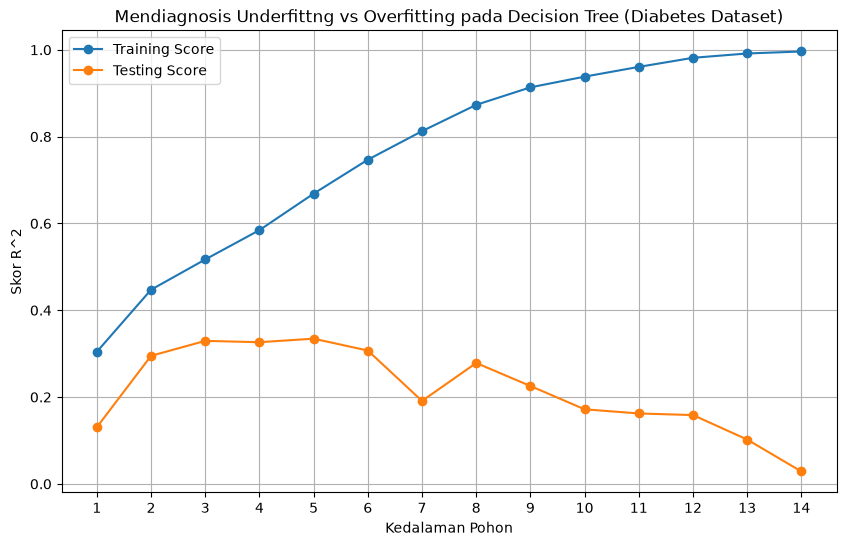

In [33]:
# Plot hasil
plt.figure(figsize=(10, 6))
plt.plot(depth_range, train_scores, "o-", label='Training Score')
plt.plot(depth_range, test_scores, "o-",label='Testing Score')

plt.xlabel("Kedalaman Pohon")
plt.ylabel("Skor R^2")
plt.title("Mendiagnosis Underfittng vs Overfitting pada Decision Tree (Diabetes Dataset)")

plt.xticks(depth_range)
plt.legend()
plt.grid(True)
plt.show()

**Cara Membaca Grafik dan Mendiagnosis Hasilnya**

1. **Fase Underfitting** (Kedalaman Sangat Rendah: max_depth = 1 - 2)
    - Gejala: Skor pada data pelatihan (Training Score) dan data pengujian (Testing Score) sama-sama rendah.
    - Analisis: Modelnya terlalu sederhana. Di kedalaman ini, decision tree hanya membuat 1 atau 2 pertanyaan saja untuk menebak kadar gula darah pasien diabetes. Model gagal menangkap pola dasar data.

2. **Fase Optimal** (Sweet Spot: Biasanya di sekitar max_depth = 3 - 5)
    - Gejala: Testing Score mencapai titik tertingginya, dan jarak (gap) antara Training Score dan Testing Score belum terlalu jauh.
    - Analisis: Di sinilah keseimbangan terbaik antara bias dan variansi. Model cukup kompleks untuk memahami pola, tapi tidak terlalu rumit sampai menghafal noise. Ini kedalaman optimal yang harus kamu pilih.

3. **Fase Overfitting** (Kedalaman Tinggi: max_depth > 6)
    - Gejala: Training Score terus meroket naik mendekati 1.0 (sempurna), tetapi Testing Score justru menurun drastis. Jarak kedua kurva melebar jauh.
    - Analisis: Model sudah mulai menghafal data latihan secara detail, termasuk noise-nya. Begitu diuji dengan data baru yang belum pernah dilihat (X_test), model menjadi bingung dan performanya anjlok.